# Fase 0 · Etapa 0.2 — Mapa do código legado e execução "como está"

> **Base de dados usada:** **dados do pesquisador** — 1ª campanha (`exp_5/`, alumínio e
> acrílico em engaste-livre, que são os casos usados por `main.py` e
> `main_otimizador.py`) e 2ª campanha livre-livre (`AÇO/`). Nenhuma base externa.

**Objetivo.** Entender o que cada função do legado faz, quem chama quem, e rodar os
dois scripts principais exatamente como foram deixados, para registrar o que funciona
e o que quebra. Achados verificados aqui: **I1** e **I2** (mais um achado novo, N1).

**Como o legado é executado:** pelo *harness* `dampid.audit.legacy_harness`, que não
altera nenhum arquivo de `legacy/`. Ele só (i) resolve os caminhos relativos dos CSVs e
(ii) troca `matrixes()` (SymPy) por uma reprodução numérica verificada, porque o SymPy
não pôde ser instalado neste ambiente.

In [1]:
import ast
import runpy
import time
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dampid.audit import legacy_harness as lh

B = lh.load_legacy()
print("matrixes() em uso:", B.__matrixes_source__)

matrixes() em uso: numeric-reproduction


## 1. Inventário de funções
Lido com `ast` (análise estática do código): tamanho de cada função e onde ela é chamada.

In [2]:
files = {p.name: p.read_text(encoding="utf-8") for p in sorted(lh.LEGACY_DIR.glob("*.py"))}
trees = {n: ast.parse(s) for n, s in files.items()}
funcs = [(n, f) for n, t in trees.items() for f in t.body if isinstance(f, ast.FunctionDef)]
calls = {}
for fname, tree in trees.items():
    for node in ast.walk(tree):
        if isinstance(node, ast.Call) and isinstance(node.func, ast.Name):
            calls.setdefault(node.func.id, set()).add(fname)
tab = pd.DataFrame([{
    "função": f.name, "arquivo": n, "linhas": f.end_lineno - f.lineno + 1,
    "chamada em": ", ".join(sorted(calls.get(f.name, []))) or "—",
} for n, f in funcs])
print(tab.to_string(index=False))

                      função            arquivo  linhas                        chamada em
               material_prop      Biblioteca.py      41                     Biblioteca.py
                    contorno      Biblioteca.py      17                     Biblioteca.py
        leitura_experimental      Biblioteca.py      28       main.py, main_otimizador.py
            pos_experimental      Biblioteca.py     120       main.py, main_otimizador.py
pos_experimental_livre_livre      Biblioteca.py     175                                 —
                    matrixes      Biblioteca.py      52                     Biblioteca.py
            calculo_numerico      Biblioteca.py      82                                 —
      calculo_numerico_modal      Biblioteca.py      85       main.py, main_otimizador.py
                       force      Biblioteca.py       5 Biblioteca.py, main_otimizador.py
                   frf_tempo      Biblioteca.py      25                                 —
          

**Fluxo de `main.py` (alumínio, engaste-livre):**

```
leitura_experimental ─► pos_experimental ─► (amplitude do martelo, FRF experimental)
                                             │
material_prop, contorno, matrixes ─► calculo_numerico_modal (solve_ivp Radau) ─► a(t) numérico
                                 └─► frf_direta_modal (solve por frequência)  ─► FRF numérica
                                             │
                               plots tempo e FRF (com fatores 9.81, 9810, 9810²)
```

**Fluxo de `main_otimizador.py` (acrílico, engaste-livre):** o mesmo pré-processamento,
e depois um algoritmo genético minimiza `−RVAC(ζ)` usando `frf_direta_modal_comparacao`.
As versões anteriores (comentadas) usavam L-BFGS-B com `−TSAC` ou `−MAC`.

Funções que **existem mas não são usadas** por nenhum script: `calculo_numerico`
(Rayleigh), `frf_tempo`, `frf_direta`, `otimizador` (vazia), `pos_experimental_livre_livre`.

## 2. Rodando `main.py` como está

main.py terminou sem erro em 0.8 s
ponto_resposta = 28 | phi_num [rad/s] = [  223.5  1401.6  3603.9  3936.6  7776.8 12907.5]
frequências correspondentes [Hz] = [  35.6  223.1  573.6  626.5 1237.7 2054.3]


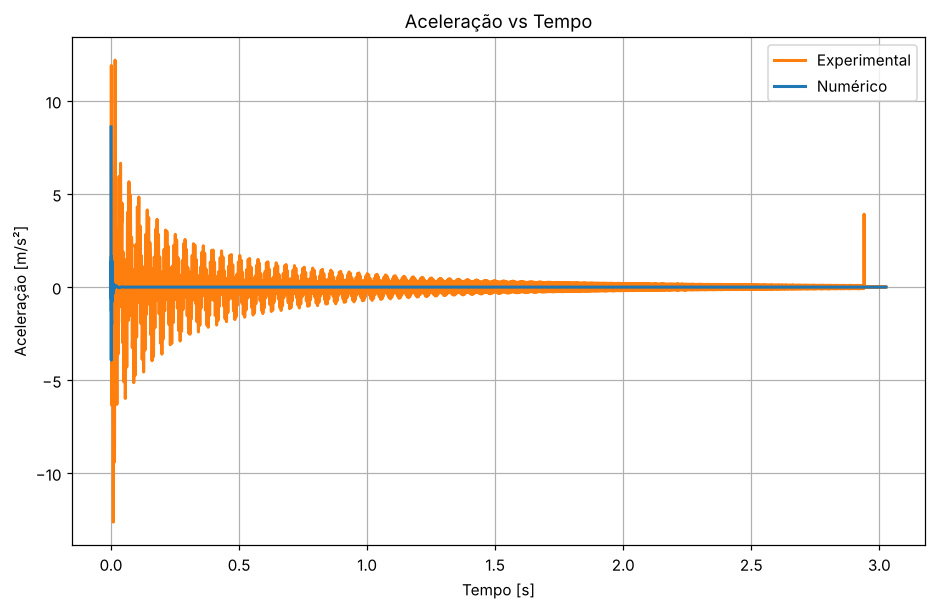

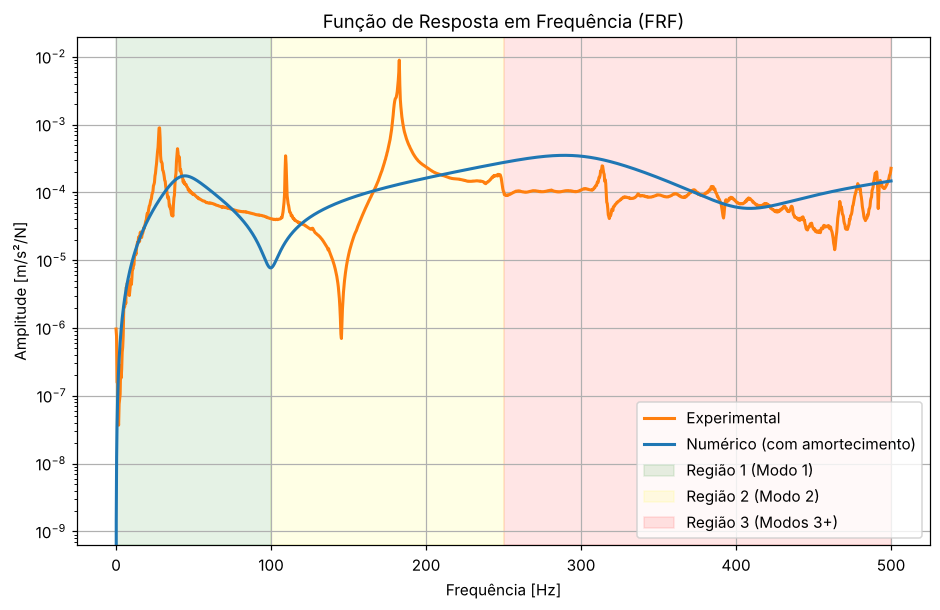

In [3]:
with lh.legacy_workdir():
    t0 = time.time()
    ns = runpy.run_path(str(lh.LEGACY_DIR / "main.py"), run_name="__main__")
    print(f"main.py terminou sem erro em {time.time() - t0:.1f} s")
print("ponto_resposta =", ns["ponto_resposta"], "| phi_num [rad/s] =", np.round(ns["phi_num"], 1))
print("frequências correspondentes [Hz] =", np.round(ns["phi_num"] / (2 * np.pi), 1))

As duas figuras acima são as que o `main.py` produz (aceleração no tempo e FRF). Repare
que ele **roda**, mas isso não quer dizer que esteja certo: os achados C2–C6 (escala do
amortecimento, GL de resposta, unidades, filtro) são examinados nos notebooks 02–06.

## 3. Rodando `main_otimizador.py` como está → achado **I1**

In [4]:
with lh.legacy_workdir():
    try:
        runpy.run_path(str(lh.LEGACY_DIR / "main_otimizador.py"), run_name="__main__")
    except Exception as e:
        print("FALHOU:", type(e).__name__, "-", e)
        print(traceback.format_exc().splitlines()[-3])

FALHOU: ValueError - too many values to unpack (expected 17)
        decrement_amp_second_mode, freq_frf, ampl_frf, fase_frf, tempo_picos_freq, amp_picos_freq, amplitude, alfa, beta, numero_de_modos, phi_exp = pos_experimental(material,  input_tempo, input_aceleracao, input_martelo, numero_de_pontos = 6)


In [5]:
ret = next(f for n, f in funcs if f.name == "pos_experimental")
n_ret = len(next(x for x in ast.walk(ret) if isinstance(x, ast.Return)).value.elts)
assign = next(x for x in ast.walk(trees["main_otimizador.py"])
              if isinstance(x, ast.Assign) and isinstance(x.targets[0], ast.Tuple)
              and getattr(x.value, "func", None) is not None and getattr(x.value.func, "id", "") == "pos_experimental")
names = [t.id for t in assign.targets[0].elts]
ret_names = [getattr(e, "id", "?") for e in next(x for x in ast.walk(ret) if isinstance(x, ast.Return)).value.elts]
print(f"pos_experimental devolve {n_ret} valores; main_otimizador desempacota {len(names)}.")
cmp = pd.DataFrame({"posição": range(1, n_ret + 1), "pos_experimental devolve": ret_names,
                    "main_otimizador espera": names + ["(sobra)"] * (n_ret - len(names))})
print(cmp.to_string(index=False))

pos_experimental devolve 18 valores; main_otimizador desempacota 17.
 posição    pos_experimental devolve      main_otimizador espera
       1               tempo_cortado                   exp_tempo
       2          aceleracao_cortada              exp_aceleracao
       3             martelo_cortado                 exp_martelo
       4             decrement_peaks             decrement_peaks
       5               decrement_amp               decrement_amp
       6 decrement_peaks_second_mode decrement_peaks_second_mode
       7   decrement_amp_second_mode   decrement_amp_second_mode
       8                    freq_frf                    freq_frf
       9                    ampl_frf                    ampl_frf
      10             signal_filtered                    fase_frf
      11                    fase_frf            tempo_picos_freq
      12            tempo_picos_freq              amp_picos_freq
      13              amp_picos_freq                   amplitude
      14             

**Confirmado (I1).** O script de otimização não roda: `pos_experimental` ganhou o
retorno `signal_filtered` (posição 10) e o `main_otimizador.py` não foi atualizado.
Se alguém "consertasse" só a contagem, as variáveis ficariam **deslocadas** a partir da
posição 10 (`fase_frf` receberia a FRF filtrada etc.). Ou seja, os resultados de
otimização da monografia vieram de uma versão anterior do código, que não está no
repositório.

## 4. Condição de contorno livre-livre → achado **I2**

In [6]:
for cc in ["engastado_livre", "engastado_engastado", "livre"]:
    try:
        b, free, nfree, pr = B.contorno(cc, 6, 6)
        print(f"{cc:<20} OK  graus livres = {nfree}, ponto_resposta = {pr}")
    except Exception as e:
        print(f"{cc:<20} FALHOU: {type(e).__name__}: {e}")

engastado_livre      OK  graus livres = 30, ponto_resposta = 28
engastado_engastado  OK  graus livres = 24, ponto_resposta = 9
livre                FALHOU: UnboundLocalError: cannot access local variable 'ponto_resposta' where it is not associated with a value


**Confirmado (I2).** `contorno("livre")` não define `ponto_resposta` e quebra. Além
disso, nenhuma função numérica aplica força para `cc == "livre"` (os `if` só tratam
engaste-livre e engaste-engaste). Ou seja, o modelo numérico legado **não simula a 2ª
campanha** (livre-livre), que é justamente a de melhor qualidade.

## 5. Pós-processamento livre-livre do legado (só experimental)

In [7]:
with lh.legacy_workdir():
    for max_time in (4.0, 3.5):
        try:
            t0 = time.time()
            out = B.pos_experimental_livre_livre("aco", 500, max_time, 16)
            print(f"max_time={max_time} s: OK em {time.time() - t0:.1f} s")
            break
        except Exception as e:
            print(f"max_time={max_time} s: FALHOU — {type(e).__name__}: {e}")

max_time=4.0 s: FALHOU — ValueError: operands could not be broadcast together with shapes (2000,) (1987,) (2000,) 
max_time=3.5 s: OK em 6.8 s


**Achado novo N2.** Com `max_time = 4 s` a função quebra: quando o "trigger" do legado
cai depois de 1 s, sobra menos de 4 s de registro, o ramo `else` cria um vetor de tempo
mais longo que os sinais, e a FFT desse ensaio tem outro número de pontos (1987 em vez
de 2000 bins) — a média entre ensaios falha. Com 3,5 s funciona. O tempo de corte usado
na monografia não está registrado. A tabela abaixo mostra **onde o trigger do legado cai**
em cada ensaio de aço (ele usa a diferença entre amostras de aceleração > 0,05 m/s²):

In [8]:
from dampid.audit.reference import force_onset, read_ni_csv

rows = []
for i in range(1, 17):
    d = read_ni_csv(lh.RAW_DIR / "AÇO" / f"LL_ACO_{i:02d}.csv")
    acc = d["ch"][0] * 9.81
    pos = int(np.argmax(np.abs(np.diff(acc)) >= 0.05))
    rows.append({"ensaio": i, "trigger legado [s]": round(pos / d["fs"], 3),
                 "início da força [s]": round(force_onset(d["ch"][2], d["fs"]) / d["fs"], 3)})
trig = pd.DataFrame(rows)
print(trig.to_string(index=False))

 ensaio  trigger legado [s]  início da força [s]
      1               0.018                2.014
      2               0.869                0.869
      3               0.315                0.774
      4               0.928                0.928
      5               0.605                0.828
      6               0.000                0.944
      7               0.015                0.769
      8               0.201                0.976
      9               0.921                0.921
     10               0.001                0.813
     11               0.130                1.350
     12               0.748                0.748
     13               0.000                0.864
     14               0.000                1.049
     15               0.010                0.901
     16               1.027                1.027


Em vários ensaios de aço o trigger do legado dispara na **amostra 0**, muito antes do
golpe: a viga ainda vibrava do golpe anterior (achado 3 da §2.3), e a diferença entre
amostras já passa do limiar. O corte fica então desalinhado do impacto. Isso alimenta o
achado I11 (notebook 06).
freq, a1, a2 = out[8], out[5], out[6]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.semilogy(freq, a1, lw=0.8, label="sensor 1 (média de |·| do legado)")
ax.semilogy(freq, a2, lw=0.8, label="sensor 2")
ax.set(xlabel="Frequência [Hz]", ylabel="'FRF' legado [unid. do legado]",
       title="Aço livre-livre — saída de pos_experimental_livre_livre (legado)")
ax.legend(); ax.grid(alpha=0.3)

Roda, mas faz média de **magnitudes e fases** entre ensaios e aplica o fator `2/N` —
itens I10 e C5, tratados no notebook 06.

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| I1 | **confirmado** | `ValueError: too many values to unpack (expected 17)`; tabela de deslocamento |
| I2 | **confirmado** | `UnboundLocalError` em `contorno("livre")`; sem força para livre-livre |
| `main.py` | roda (≈1 s) | figuras acima; correção física avaliada nos notebooks seguintes |